# Dog Breed Identification using MobileNetV2

**ICS 3202 Semester Project Deliverable 2**  
**Due date:** 6 November 2026  
**GitHub repository:** `SemProject_MLEngine`

Our project is a mobile app that can identify a dog's breed from a photo. In this notebook we prepare the image data, train a MobileNetV2 model, test it, and prepare it for use in a mobile app.

We use the Stanford Dogs dataset. It has 20,580 images from 120 dog breeds. We load it from a Hugging Face mirror because the original university download server was unavailable when we tested it.

> Some cells take a long time because they check every image or train the model. The final scores shown in this notebook must come from a real completed run.

## 1. What we are trying to solve

The model receives a dog photo and predicts the breed. This is a classification problem because every image belongs to one of 120 breed classes.

We chose MobileNetV2 because it already knows useful image features from ImageNet and it is small enough for a mobile application. We first train a new output layer, then carefully fine-tune some of the pretrained layers.

We keep separate training, validation, and test sets. The test set is not used while training. It is only used at the end to check how the model performs on unseen images.

In [ ]:
# COLAB SETUP — run this cell first. importlib-resources is required by
# TensorFlow Datasets on some current Colab/Python images.
%pip install -q importlib-resources datasets scikit-learn seaborn pandas pillow

import os, random, hashlib, json, sys, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from datasets import load_dataset, concatenate_datasets
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, top_k_accuracy_score,
                             precision_recall_fscore_support)

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS_HEAD = 10
EPOCHS_FINE = 8
RUN_TRAINING = True  # TRAINING REQUIRED: change to True on a GPU runtime
RUN_CV = False        # Optional, expensive validation experiment
ARTIFACT_DIR = Path('artifacts')
ARTIFACT_DIR.mkdir(exist_ok=True)

os.environ['TF_DETERMINISTIC_OPS'] = '1'
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print('Python:', sys.version.split()[0], '| TensorFlow:', tf.__version__)
print('GPU(s):', tf.config.list_physical_devices('GPU'))
print('RUN_TRAINING =', RUN_TRAINING, '| RUN_CV =', RUN_CV)

Python: 3.13.16 | TensorFlow: 2.21.0
GPU(s): [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
RUN_TRAINING = True | RUN_CV = False


## 2. Getting the dataset

We use the original Stanford Dogs images and labels from the public Hugging Face mirror `maurice-fp/stanford-dogs`. The data is stored in cloud-hosted Parquet files, so we do not need a Kaggle token or the unavailable Stanford server.

The original train and test parts are joined because we create our own stratified 70/15/15 split. The first download needs internet access and around 1.5 GB of storage.

In [ ]:
# DATA DOWNLOAD REQUIRED on the first run.
# Cloud-hosted mirror of the original Stanford Dogs images and labels.
hf = load_dataset('maurice-fp/stanford-dogs')
assert {'train', 'test'}.issubset(hf.keys())
hf_all = concatenate_datasets([hf['train'], hf['test']])

label_feature = hf['train'].features['label']
class_names = np.array(label_feature.names)
NUM_CLASSES = len(class_names)
N_TOTAL = len(hf_all)
assert N_TOTAL == 20580, f'Expected 20,580 images, found {N_TOTAL}'
assert NUM_CLASSES == 120, f'Expected 120 breeds, found {NUM_CLASSES}'

def image_array(example):
    """Normalize PIL images to RGB uint8 arrays."""
    return np.asarray(example['image'].convert('RGB'), dtype=np.uint8)

def all_examples_generator():
    for example in hf_all:
        yield image_array(example), np.int64(example['label'])

raw_all = tf.data.Dataset.from_generator(
    all_examples_generator,
    output_signature=(tf.TensorSpec((None, None, 3), tf.uint8),
                      tf.TensorSpec((), tf.int64)))

print(f'{N_TOTAL:,} dog images; {NUM_CLASSES} dog breeds')
print('Example classes:', class_names[:8].tolist())

20,580 dog images; 120 dog breeds
Example classes: ['n02085620-Chihuahua', 'n02085782-Japanese_spaniel', 'n02085936-Maltese_dog', 'n02086079-Pekinese', 'n02086240-Shih-Tzu', 'n02086646-Blenheim_spaniel', 'n02086910-papillon', 'n02087046-toy_terrier']


## 3. Checking and understanding the data

Before training, we need to know whether the data has problems. We check that images can open, have three colour channels, have valid labels, and are not exact duplicates. We also look at breed counts, image sizes, and image shapes.

All observations printed below are calculated from the dataset. They are not values typed in by hand.

In [ ]:
# One pass: collect metadata and exact hashes. This may take several minutes.
rows = []
bad_indices = []
for i, (image, label) in enumerate(raw_all.as_numpy_iterator()):
    try:
        arr = np.asarray(image)
        valid = arr.ndim == 3 and arr.shape[2] == 3 and arr.shape[0] > 0 and arr.shape[1] > 0
        digest = hashlib.sha256(arr.tobytes()).hexdigest() if valid else None
        rows.append((i, int(label), arr.shape[0], arr.shape[1], arr.shape[2] if arr.ndim == 3 else -1,
                     digest, valid))
        if not valid: bad_indices.append(i)
    except Exception as exc:
        rows.append((i, -1, np.nan, np.nan, -1, None, False)); bad_indices.append(i)

meta = pd.DataFrame(rows, columns=['index','label','height','width','channels','sha256','valid'])
meta['breed'] = meta['label'].map(lambda x: class_names[x] if 0 <= x < NUM_CLASSES else 'INVALID')
meta['aspect_ratio'] = meta['width'] / meta['height']
dup_mask = meta['valid'] & meta.duplicated('sha256', keep='first')
clean_meta = meta[meta['valid'] & ~dup_mask].copy()

print('Raw:', len(meta), '| invalid:', (~meta.valid).sum(), '| duplicate copies:', dup_mask.sum(),
      '| retained:', len(clean_meta))
assert clean_meta['label'].between(0, NUM_CLASSES - 1).all()
assert clean_meta['sha256'].is_unique
display(clean_meta.head())

Raw: 20580 | invalid: 0 | duplicate copies: 89 | retained: 20491


,index,label,height,width,channels,sha256,valid,breed,aspect_ratio
0,0,0,298,500,3,099fe8e4d46a585f757b0ed1355c2504ed71d0b3542234...,True,n02085620-Chihuahua,1.677852
1,1,0,484,322,3,9f4f98a0a691d0cf9be0f47c31da427139cec20c44e9b2...,True,n02085620-Chihuahua,0.665289
2,2,0,375,500,3,d0634bc44ad9971822b41d9cd9a5793527449b02b35961...,True,n02085620-Chihuahua,1.333333
3,3,0,384,382,3,f1d0f2f4a4b89c6d81a7d808096f4255380756556ad041...,True,n02085620-Chihuahua,0.994792
4,4,0,500,375,3,b82f72b5801f344c7bb9ac4192841d5df41cbc31757548...,True,n02085620-Chihuahua,0.750000


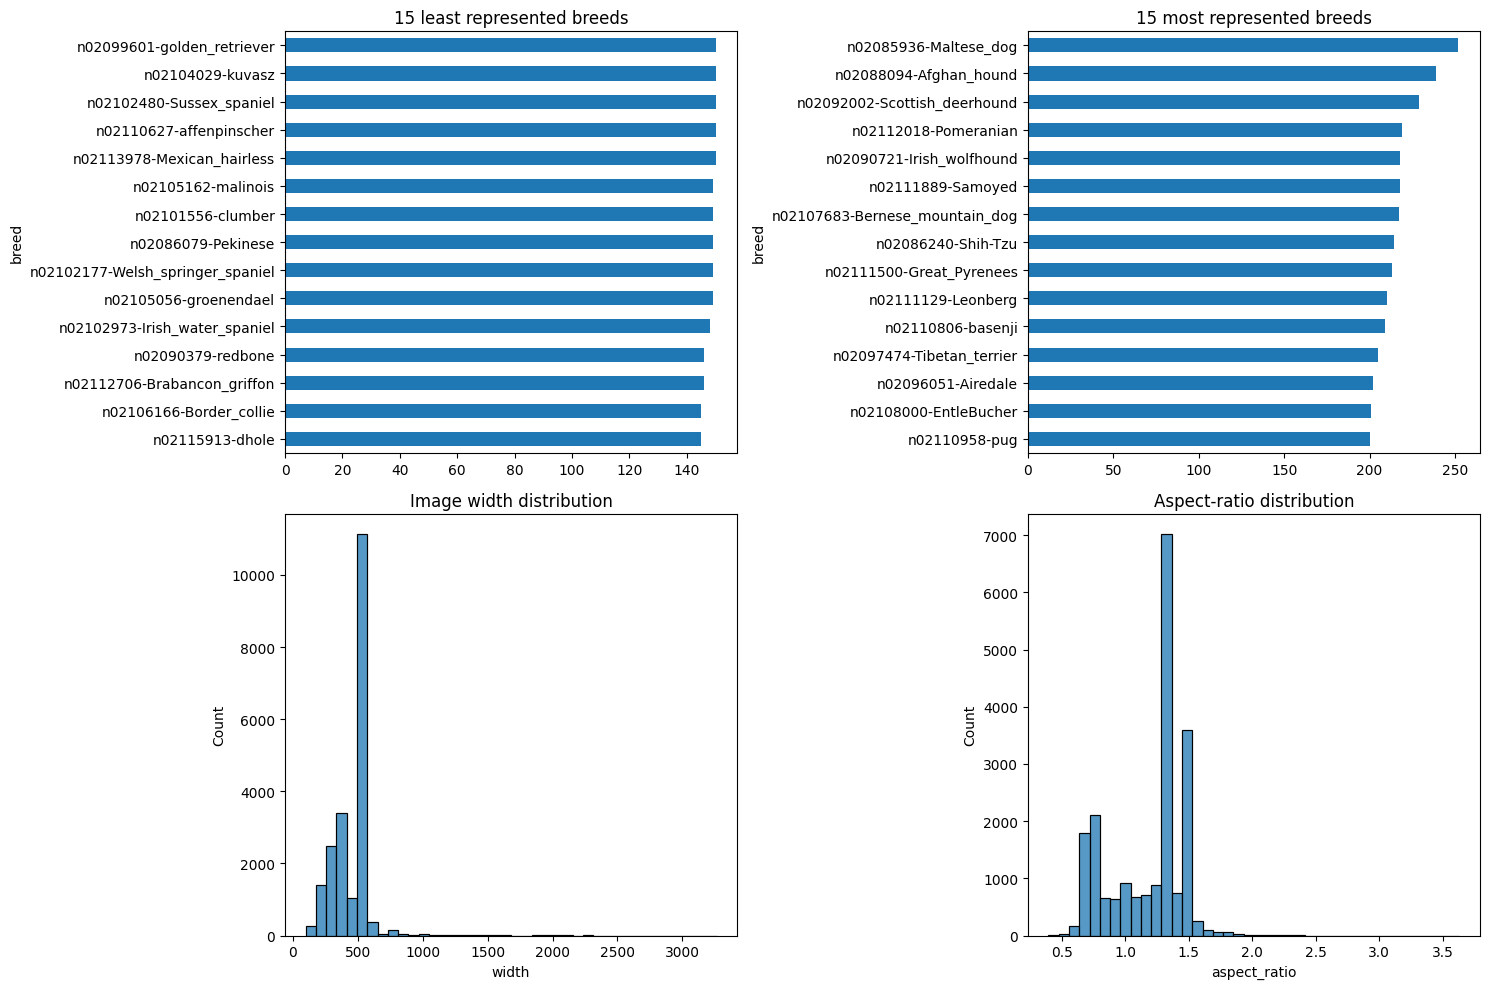

,value
retained_images,20491.000000
breeds,120.000000
min_images_per_breed,145.000000
median_images_per_breed,159.500000
max_images_per_breed,252.000000
imbalance_ratio_max_div_min,1.737931
median_width,500.000000
median_height,375.000000
portrait_pct,27.768289
landscape_pct,70.479723


In [ ]:
# Dataset-derived summaries and plots
counts = clean_meta['breed'].value_counts()
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
counts.sort_values().head(15).plot.barh(ax=axes[0,0], title='15 least represented breeds')
counts.head(15).sort_values().plot.barh(ax=axes[0,1], title='15 most represented breeds')
sns.histplot(clean_meta['width'], bins=40, ax=axes[1,0]); axes[1,0].set_title('Image width distribution')
sns.histplot(clean_meta['aspect_ratio'], bins=40, ax=axes[1,1]); axes[1,1].set_title('Aspect-ratio distribution')
plt.tight_layout(); plt.show()

summary = pd.Series({
    'retained_images': len(clean_meta), 'breeds': clean_meta.breed.nunique(),
    'min_images_per_breed': int(counts.min()), 'median_images_per_breed': float(counts.median()),
    'max_images_per_breed': int(counts.max()), 'imbalance_ratio_max_div_min': float(counts.max()/counts.min()),
    'median_width': float(clean_meta.width.median()), 'median_height': float(clean_meta.height.median()),
    'portrait_pct': float((clean_meta.aspect_ratio < 1).mean()*100),
    'landscape_pct': float((clean_meta.aspect_ratio > 1).mean()*100),
})
display(summary.to_frame('value'))

In [ ]:
# At least four EDA observations, generated from the dataset rather than invented.
observations = [
    f"1. After validation and exact de-duplication, {len(clean_meta):,} of {len(meta):,} images remain; "
    f"{(~meta.valid).sum()} invalid and {dup_mask.sum()} duplicate copies were excluded.",
    f"2. The retained dataset contains {clean_meta.breed.nunique()} breeds. Class counts range from "
    f"{counts.min()} ({counts.idxmin()}) to {counts.max()} ({counts.idxmax()}), a {counts.max()/counts.min():.2f}:1 ratio.",
    f"3. Image dimensions are not uniform: widths range from {clean_meta.width.min()} to {clean_meta.width.max()} px "
    f"and heights from {clean_meta.height.min()} to {clean_meta.height.max()} px; resizing is therefore required.",
    f"4. Orientation varies: {(clean_meta.aspect_ratio < 1).mean()*100:.1f}% portrait, "
    f"{(clean_meta.aspect_ratio > 1).mean()*100:.1f}% landscape, and "
    f"{(clean_meta.aspect_ratio == 1).mean()*100:.1f}% square; augmentation should not assume one aspect ratio.",
    f"5. Median resolution is {clean_meta.width.median():.0f}×{clean_meta.height.median():.0f} px. "
    f"The model standardizes inputs to {IMG_SIZE[0]}×{IMG_SIZE[1]} for batching and MobileNetV2 compatibility."
]
print('\n'.join(observations))

1. After validation and exact de-duplication, 20,491 of 20,580 images remain; 0 invalid and 89 duplicate copies were excluded.
2. The retained dataset contains 120 breeds. Class counts range from 145 (n02106166-Border_collie) to 252 (n02085936-Maltese_dog), a 1.74:1 ratio.
3. Image dimensions are not uniform: widths range from 97 to 3264 px and heights from 100 to 2562 px; resizing is therefore required.
4. Orientation varies: 27.8% portrait, 70.5% landscape, and 1.8% square; augmentation should not assume one aspect ratio.
5. Median resolution is 500×375 px. The model standardizes inputs to 224×224 for batching and MobileNetV2 compatibility.


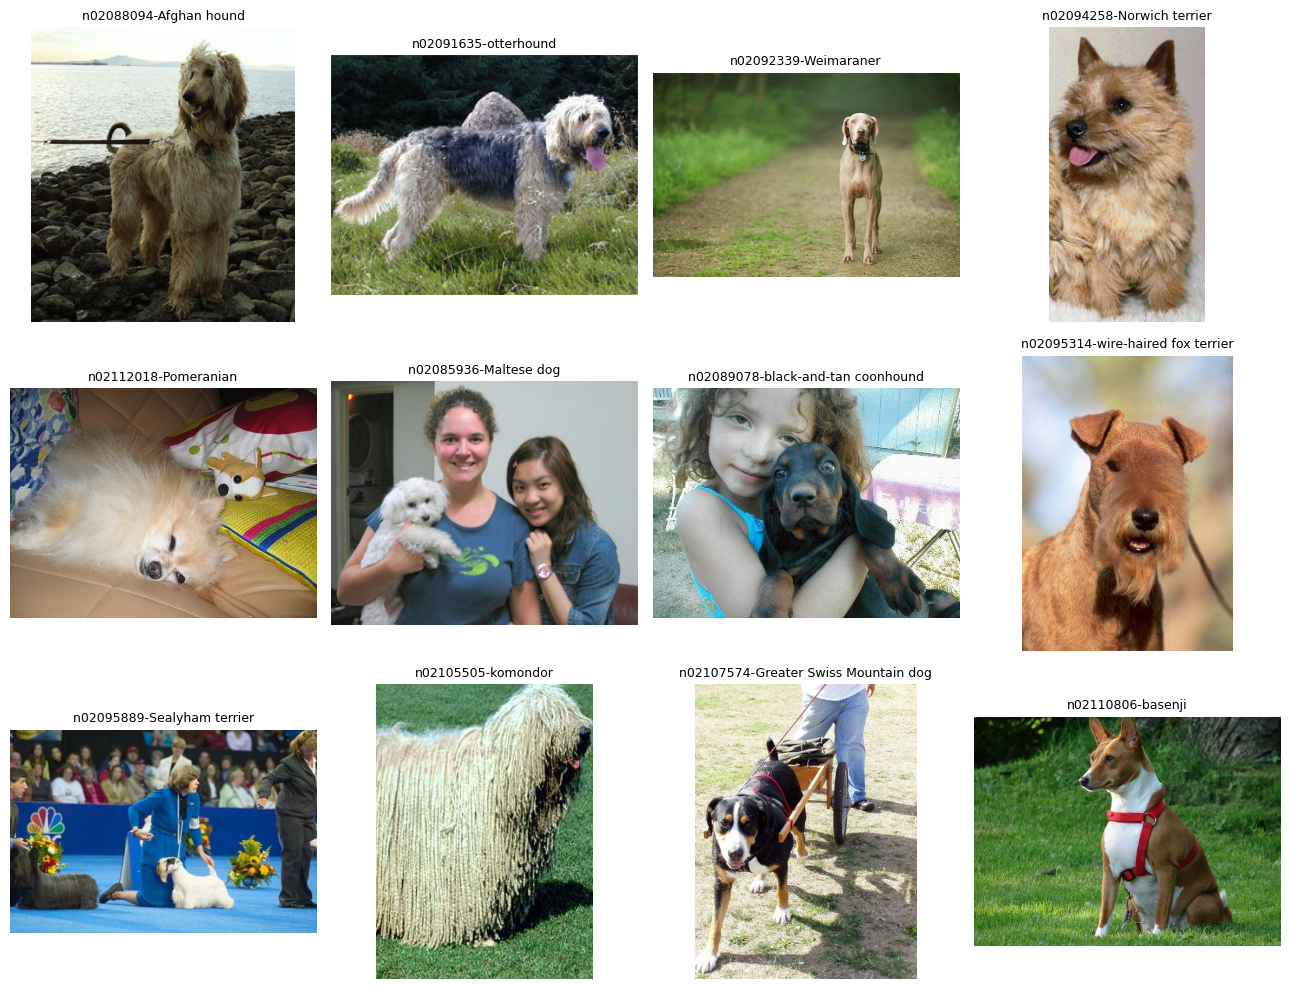

In [ ]:
# Display random samples with labels (visual label/quality sanity check).
sample_rows = clean_meta.sample(12, random_state=SEED)
sample_ids = set(sample_rows['index'].tolist())
fig, axes = plt.subplots(3, 4, figsize=(13, 10)); axes = axes.ravel(); j = 0
for i, (image, label) in enumerate(raw_all.as_numpy_iterator()):
    if i in sample_ids:
        axes[j].imshow(image); axes[j].set_title(class_names[int(label)].replace('_',' '), fontsize=9)
        axes[j].axis('off'); j += 1
        if j == len(axes): break
plt.tight_layout(); plt.show()

### Cleaning choices

- We remove images that cannot be read or do not have a valid RGB shape.
- We remove exact duplicate images so the same picture cannot appear in two splits.
- We confirm that every label belongs to one of the 120 breeds.
- We resize images to 224×224 because MobileNetV2 needs one fixed input size.
- We only augment training images. This gives the model more variety without changing validation or test images.
- We use class weights so breeds with fewer images are not ignored.

Exact hashing only finds identical copies. A resized or slightly edited copy may not have the same hash, which is a limitation of this cleaning step.

## 4. Splitting the data

We use 70% of the cleaned images for training, 15% for validation, and 15% for final testing. The split is stratified, meaning each breed keeps roughly the same proportion in all three groups.

The checks below confirm that the groups do not overlap and that all 120 breeds are represented.

In [ ]:
indices = clean_meta['index'].to_numpy()
labels = clean_meta['label'].to_numpy()
train_idx, temp_idx, y_train, y_temp = train_test_split(
    indices, labels, test_size=0.30, stratify=labels, random_state=SEED)
val_idx, test_idx, y_val, y_test = train_test_split(
    temp_idx, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

assert not (set(train_idx) & set(val_idx) or set(train_idx) & set(test_idx) or set(val_idx) & set(test_idx))
assert set(np.unique(y_train)) == set(range(NUM_CLASSES))
assert set(np.unique(y_val)) == set(range(NUM_CLASSES))
assert set(np.unique(y_test)) == set(range(NUM_CLASSES))
print('train:', len(train_idx), 'validation:', len(val_idx), 'test:', len(test_idx))

def proportion_table(name, ys):
    return pd.Series(ys).value_counts(normalize=True).rename(name)
display(pd.concat([proportion_table('train', y_train), proportion_table('val', y_val),
                   proportion_table('test', y_test)], axis=1).describe())

train: 14343 validation: 3074 test: 3074


,train,val,test
count,120.000000,120.000000,120.000000
mean,0.008333,0.008333,0.008333
std,0.001139,0.001168,0.001136
min,0.007111,0.006831,0.006831
25%,0.007390,0.007482,0.007482
50%,0.007774,0.007807,0.007807
75%,0.009064,0.009109,0.008865
max,0.012271,0.012362,0.012362


In [ ]:
# Read selected Arrow rows lazily without loading all images into RAM.
def selected_examples_generator(selected):
    for i in np.asarray(selected, dtype=np.int64):
        example = hf_all[int(i)]
        yield image_array(example), np.int64(example['label'])

augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'), tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.12), tf.keras.layers.RandomContrast(0.12)
], name='training_augmentation')

def prepare(image, label, training=False):
    image = tf.image.resize(image, IMG_SIZE, antialias=True)
    image = tf.cast(image, tf.float32)
    if training: image = augment(image, training=True)
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    return image, label

def make_ds(selected, training=False):
    selected = np.asarray(selected, dtype=np.int64)
    ds = tf.data.Dataset.from_generator(
        lambda: selected_examples_generator(selected),
        output_signature=(tf.TensorSpec((None, None, 3), tf.uint8),
                          tf.TensorSpec((), tf.int64)))
    if training: ds = ds.shuffle(min(len(selected), 5000), seed=SEED, reshuffle_each_iteration=True)
    return (ds.map(lambda x,y: prepare(x,y,training), num_parallel_calls=tf.data.AUTOTUNE)
            .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))

train_ds, val_ds, test_ds = make_ds(train_idx, True), make_ds(val_idx), make_ds(test_idx)
xb, yb = next(iter(train_ds)); print(xb.shape, yb.shape, float(tf.reduce_min(xb)), float(tf.reduce_max(xb)))

(32, 224, 224, 3) (32,) -1.0 1.0


## 5. Building the MobileNetV2 model

MobileNetV2 has already learned general image patterns such as edges, shapes, and textures from ImageNet. At first we freeze those pretrained layers and train only our new dog-breed output layer.

Global average pooling keeps the model smaller. Dropout and L2 regularisation help reduce overfitting. Early stopping keeps the best model instead of continuing when validation performance stops improving.

In [ ]:
tf.keras.backend.clear_session()
base = tf.keras.applications.MobileNetV2(input_shape=(*IMG_SIZE, 3), include_top=False,
                                         weights='imagenet')
base.trainable = False
inputs = tf.keras.Input((*IMG_SIZE, 3), name='image')
x = base(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.30)(x)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax',
                                kernel_regularizer=tf.keras.regularizers.l2(1e-4), name='breed')(x)
model = tf.keras.Model(inputs, outputs, name='dog_breed_mobilenetv2')
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy',
              metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name='top1'),
                       tf.keras.metrics.SparseTopKCategoricalAccuracy(k=5, name='top5')])
model.summary()

Model: "dog_breed_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ breed (Dense)                   │ (None, 120)            │       153,720 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,411,704 (9.20 MB)

 Trainable params: 153,720 (600.47 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
# Class weights are calculated only from the training partition.
train_counts = np.bincount(y_train, minlength=NUM_CLASSES)
class_weight = {i: len(y_train)/(NUM_CLASSES*count) for i, count in enumerate(train_counts)}
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2, min_lr=1e-7),
    tf.keras.callbacks.ModelCheckpoint(ARTIFACT_DIR/'best_mobilenetv2.keras', monitor='val_loss', save_best_only=True)
]

# TRAINING REQUIRED. No metrics exist until RUN_TRAINING=True and this cell completes.
history_head = None
if RUN_TRAINING:
    history_head = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD,
                             class_weight=class_weight, callbacks=callbacks)
else:
    print('SKIPPED: set RUN_TRAINING=True to train and generate genuine results.')

Epoch 1/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 354s 755ms/step - loss: 0.7732 - top1: 0.7813 - top5: 0.9663 - val_loss: 0.6305 - val_top1: 0.8208 - val_top5: 0.9789 - learning_rate: 1.0000e-05
Epoch 2/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 343s 732ms/step - loss: 0.7236 - top1: 0.7928 - top5: 0.9715 - val_loss: 0.6160 - val_top1: 0.8240 - val_top5: 0.9759 - learning_rate: 1.0000e-05
Epoch 3/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 353s 752ms/step - loss: 0.6935 - top1: 0.8039 - top5: 0.9727 - val_loss: 0.6079 - val_top1: 0.8247 - val_top5: 0.9798 - learning_rate: 1.0000e-05
Epoch 4/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 346s 736ms/step - loss: 0.6666 - top1: 0.8112 - top5: 0.9751 - val_loss: 0.6067 - val_top1: 0.8263 - val_top5: 0.9815 - learning_rate: 1.0000e-05
Epoch 5/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 345s 732ms/step - loss: 0.6506 - top1: 0.8162 - top5: 0.9773 - val_loss: 0.6132 - val_top1: 0.8279 - val_top5: 0.9782 - learning_rate: 1.0000e-05
Epoch 6/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 348s 742ms/step - loss: 0.6293

In [ ]:
# Optional fine-tuning: unfreeze the last 30 base layers with a much smaller learning rate.
history_fine = None
if RUN_TRAINING:
    base.trainable = True
    for layer in base.layers[:-30]: layer.trainable = False
    # Keep BatchNorm frozen for stable transfer learning on a modest dataset.
    for layer in base.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization): layer.trainable = False
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
                  loss='sparse_categorical_crossentropy',
                  metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name='top1'),
                           tf.keras.metrics.SparseTopKCategoricalAccuracy(k=5, name='top5')])
    history_fine = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FINE,
                             class_weight=class_weight, callbacks=callbacks)
else:
    print('SKIPPED: fine-tuning requires a trained head.')

Epoch 1/8
449/449 ━━━━━━━━━━━━━━━━━━━━ 383s 804ms/step - loss: 0.5515 - top1: 0.8456 - top5: 0.9825 - val_loss: 0.5898 - val_top1: 0.8312 - val_top5: 0.9798 - learning_rate: 1.0000e-05
Epoch 2/8
449/449 ━━━━━━━━━━━━━━━━━━━━ 373s 795ms/step - loss: 0.5363 - top1: 0.8486 - top5: 0.9847 - val_loss: 0.5949 - val_top1: 0.8331 - val_top5: 0.9776 - learning_rate: 1.0000e-05
Epoch 3/8
449/449 ━━━━━━━━━━━━━━━━━━━━ 367s 784ms/step - loss: 0.5121 - top1: 0.8546 - top5: 0.9863 - val_loss: 0.5918 - val_top1: 0.8328 - val_top5: 0.9782 - learning_rate: 2.0000e-06


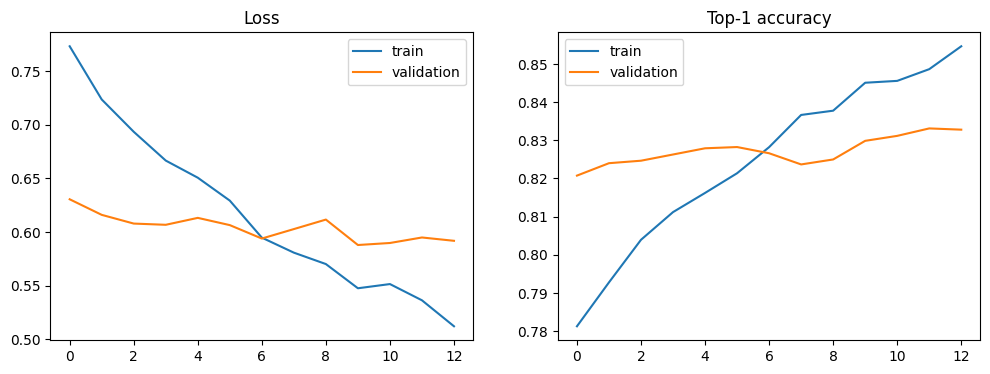

In [ ]:
def plot_histories(*histories):
    merged = {}
    for h in histories:
        if h:
            for k, v in h.history.items(): merged.setdefault(k, []).extend(v)
    if not merged: print('No training history yet.'); return
    fig, axes = plt.subplots(1, 2, figsize=(12,4))
    axes[0].plot(merged['loss'], label='train'); axes[0].plot(merged['val_loss'], label='validation')
    axes[0].set_title('Loss'); axes[0].legend()
    axes[1].plot(merged['top1'], label='train'); axes[1].plot(merged['val_top1'], label='validation')
    axes[1].set_title('Top-1 accuracy'); axes[1].legend(); plt.show()
plot_histories(history_head, history_fine)

## 6. Testing the trained model

The test images were not used to train or choose the model. We now use them to get the final scores.

Top-1 accuracy checks whether the first prediction is correct. Top-5 accuracy checks whether the correct breed appears in the model's five best guesses. Macro F1 gives every breed equal importance, while weighted F1 also considers how many images each breed has.

The next cells only show results after real training has finished.

In [ ]:
if RUN_TRAINING:
    best_model = tf.keras.models.load_model(ARTIFACT_DIR/'best_mobilenetv2.keras')
    probabilities = best_model.predict(test_ds, verbose=1)
    y_true = np.concatenate([y.numpy() for _, y in test_ds])
    y_pred = probabilities.argmax(axis=1)
    p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(
        y_true, y_pred, average='macro', zero_division=0)
    p_weight, r_weight, f1_weight, _ = precision_recall_fscore_support(
        y_true, y_pred, average='weighted', zero_division=0)
    metrics = {
        'top1_accuracy': accuracy_score(y_true, y_pred),
        'top5_accuracy': top_k_accuracy_score(y_true, probabilities, k=5, labels=np.arange(NUM_CLASSES)),
        'macro_precision': p_macro, 'macro_recall': r_macro, 'macro_f1': f1_macro,
        'weighted_precision': p_weight, 'weighted_recall': r_weight, 'weighted_f1': f1_weight
    }
    display(pd.Series(metrics).to_frame('test_value'))
    report = pd.DataFrame(classification_report(y_true, y_pred, target_names=class_names,
                                                 output_dict=True, zero_division=0)).T
    display(report)
    report.to_csv(ARTIFACT_DIR/'classification_report.csv')
    with open(ARTIFACT_DIR/'test_metrics.json','w') as f: json.dump(metrics, f, indent=2)
else:
    print('NO RESULTS REPORTED: train the model first.')

97/97 ━━━━━━━━━━━━━━━━━━━━ 30s 297ms/step


,test_value
top1_accuracy,0.825634
top5_accuracy,0.977879
macro_precision,0.830361
macro_recall,0.822551
macro_f1,0.821618
weighted_precision,0.831724
weighted_recall,0.825634
weighted_f1,0.824066


,precision,recall,f1-score,support
n02085620-Chihuahua,0.900000,0.782609,0.837209,23.000000
n02085782-Japanese_spaniel,0.962963,0.962963,0.962963,27.000000
n02085936-Maltese_dog,0.878788,0.763158,0.816901,38.000000
n02086079-Pekinese,0.800000,0.727273,0.761905,22.000000
n02086240-Shih-Tzu,0.696970,0.718750,0.707692,32.000000
...,...,...,...,...
n02115913-dhole,0.916667,1.000000,0.956522,22.000000
n02116738-African_hunting_dog,1.000000,0.960000,0.979592,25.000000
accuracy,0.825634,0.825634,0.825634,0.825634
macro avg,0.830361,0.822551,0.821618,3074.000000


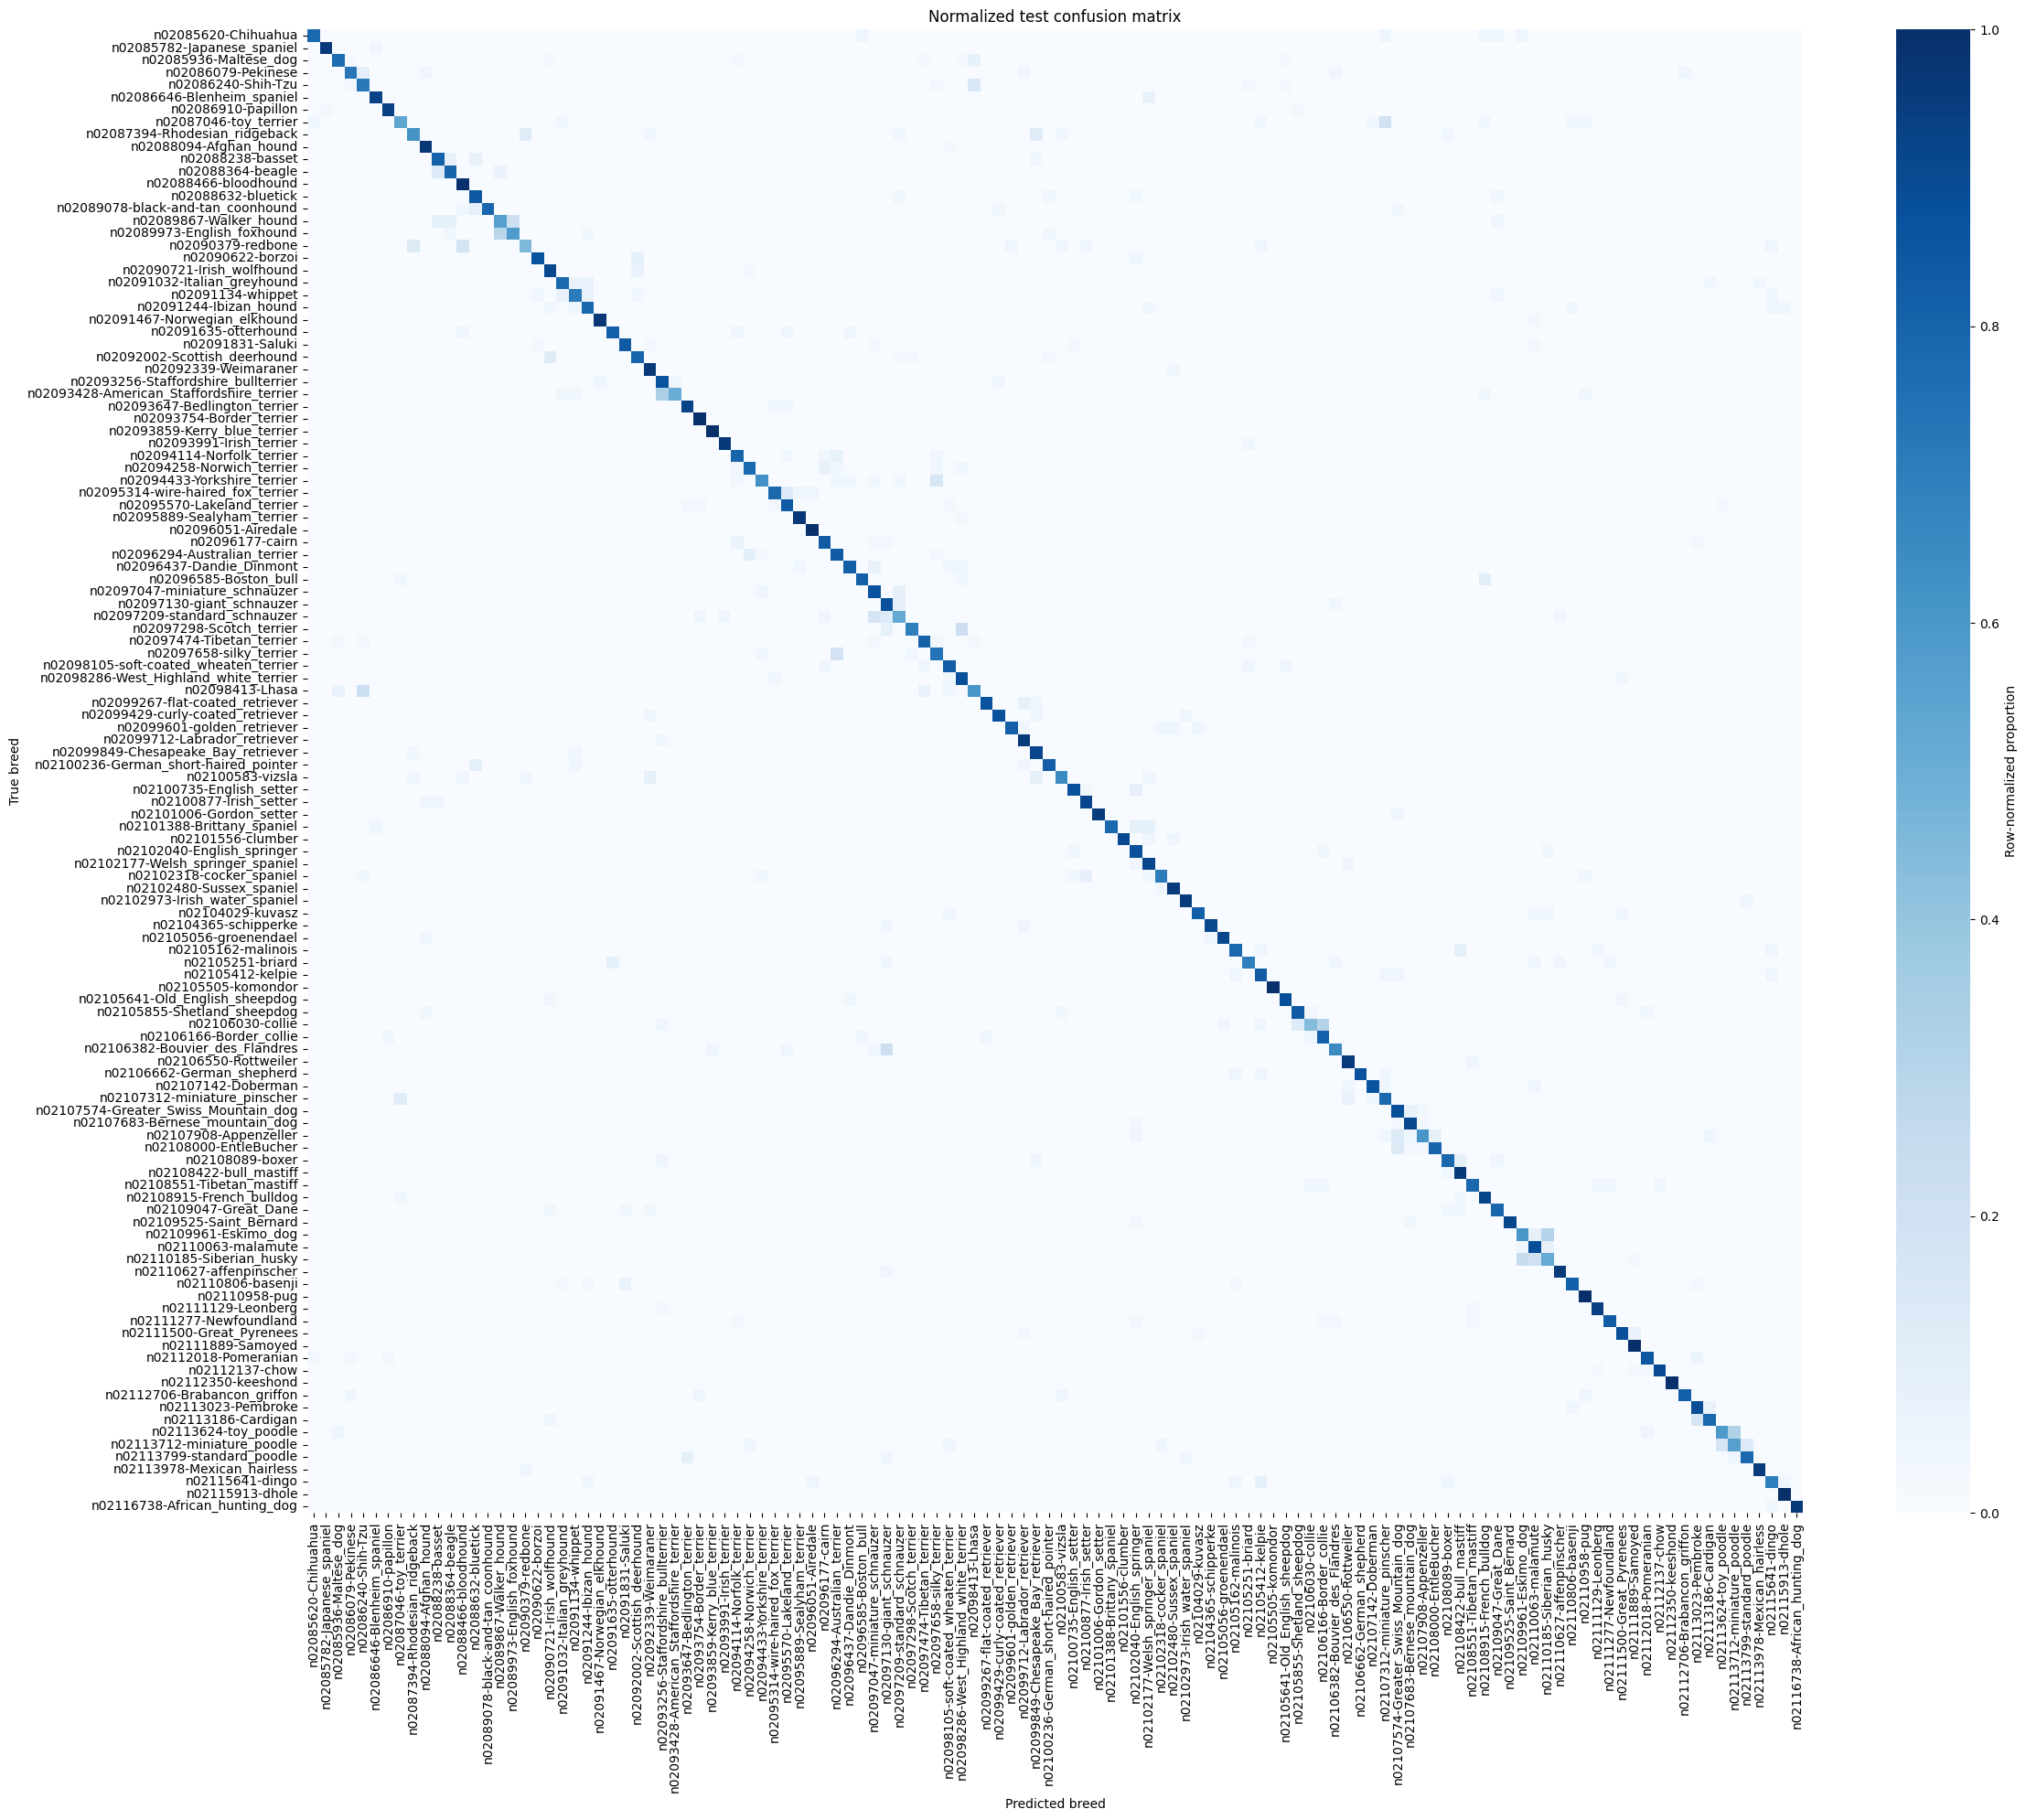

,true,predicted,confidence
2555,n02097047-miniature_schnauzer,n02094433-Yorkshire_terrier,0.993956
1276,n02092002-Scottish_deerhound,n02090721-Irish_wolfhound,0.993915
4,n02088238-basset,n02088364-beagle,0.992076
1572,n02097298-Scotch_terrier,n02098286-West_Highland_white_terrier,0.989283
1688,n02097209-standard_schnauzer,n02097047-miniature_schnauzer,0.984503
2961,n02092002-Scottish_deerhound,n02090721-Irish_wolfhound,0.983943
266,n02106030-collie,n02105056-groenendael,0.978265
1055,n02096294-Australian_terrier,n02094258-Norwich_terrier,0.975160
1965,n02087394-Rhodesian_ridgeback,n02099849-Chesapeake_Bay_retriever,0.974668
170,n02107908-Appenzeller,n02107574-Greater_Swiss_Mountain_dog,0.972017


In [ ]:
if RUN_TRAINING:
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES), normalize='true')
    plt.figure(figsize=(24,20))
    sns.heatmap(cm, cmap='Blues', xticklabels=class_names, yticklabels=class_names,
                vmin=0, vmax=1, cbar_kws={'label':'Row-normalized proportion'})
    plt.xlabel('Predicted breed'); plt.ylabel('True breed'); plt.title('Normalized test confusion matrix')
    plt.tight_layout(); plt.savefig(ARTIFACT_DIR/'confusion_matrix.png', dpi=180); plt.show()

    errors = pd.DataFrame({'true': class_names[y_true], 'predicted': class_names[y_pred],
                           'confidence': probabilities.max(axis=1)})
    display(errors[errors.true != errors.predicted].sort_values('confidence', ascending=False).head(20))
else:
    print('Confusion matrix will be generated only after genuine test predictions exist.')

## 7. Extra validation

Training the full neural network five separate times would take a lot of Colab time. Instead, our extra validation option extracts MobileNetV2 features once and tests a simpler classifier with five stratified folds.

This tells us whether performance is reasonably stable across different data splits. We report the average and standard deviation of accuracy and macro F1. These results only exist if `RUN_CV=True` and the cell finishes.

In [ ]:
# OPTIONAL VALIDATION REQUIRED; can take considerable time and RAM/disk.
if RUN_CV:
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import f1_score
    embedding_model = tf.keras.Model(model.input, model.get_layer('global_average_pooling2d').output)
    clean_ds = make_ds(indices, training=False)
    X_embed = embedding_model.predict(clean_ds, verbose=1)
    y_embed = np.concatenate([y.numpy() for _, y in clean_ds])
    rows_cv = []
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    for fold, (tr, va) in enumerate(cv.split(X_embed, y_embed), 1):
        clf = LogisticRegression(max_iter=1000, solver='lbfgs')
        clf.fit(X_embed[tr], y_embed[tr])
        pred = clf.predict(X_embed[va])
        rows_cv.append({'fold':fold, 'accuracy':accuracy_score(y_embed[va], pred),
                        'macro_f1':f1_score(y_embed[va], pred, average='macro')})
    cv_results = pd.DataFrame(rows_cv)
    display(cv_results)
    display(cv_results[['accuracy','macro_f1']].agg(['mean','std']))
    cv_results.to_csv(ARTIFACT_DIR/'embedding_cv_results.csv', index=False)
else:
    print('SKIPPED: set RUN_CV=True to generate cross-validation evidence. Do not claim CV scores yet.')

SKIPPED: set RUN_CV=True to generate cross-validation evidence. Do not claim CV scores yet.


## 8. Another model we can compare

MobileNetV2 is our base model. EfficientNetB0 is the alternative model because it is also designed to use computing power efficiently.

For a fair comparison, both models must use the same cleaned images, data splits, class weights, stopping rule, and evaluation measures. We would compare macro F1, top-1 and top-5 accuracy, model size, and phone prediction speed.

We have included the EfficientNetB0 code, but we do not claim that it performs better unless we actually train and test it.

In [ ]:
# Architecture-specific input pipeline plus reusable alternative-model factory.
# EfficientNet contains its own rescaling and therefore receives float pixels in [0, 255],
# unlike MobileNetV2's [-1, 1] preprocessing. All other split/training rules stay identical.
def prepare_efficientnet(image, label, training=False):
    image = tf.cast(tf.image.resize(image, IMG_SIZE, antialias=True), tf.float32)
    if training: image = augment(image, training=True)
    return image, label

def make_efficientnet_ds(selected, training=False):
    selected = np.asarray(selected, dtype=np.int64)
    ds = tf.data.Dataset.from_generator(
        lambda: selected_examples_generator(selected),
        output_signature=(tf.TensorSpec((None, None, 3), tf.uint8),
                          tf.TensorSpec((), tf.int64)))
    if training: ds = ds.shuffle(min(len(selected), 5000), seed=SEED, reshuffle_each_iteration=True)
    return (ds.map(lambda x,y: prepare_efficientnet(x,y,training), num_parallel_calls=tf.data.AUTOTUNE)
            .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))

def build_efficientnet_b0(num_classes=NUM_CLASSES):
    backbone = tf.keras.applications.EfficientNetB0(include_top=False, weights='imagenet',
                                                     input_shape=(*IMG_SIZE,3))
    backbone.trainable = False
    inp = tf.keras.Input((*IMG_SIZE,3)); x = backbone(inp, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x); x = tf.keras.layers.Dropout(0.30)(x)
    out = tf.keras.layers.Dense(num_classes, activation='softmax',
                                kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    alt = tf.keras.Model(inp, out, name='dog_breed_efficientnetb0')
    alt.compile(tf.keras.optimizers.Adam(1e-3), 'sparse_categorical_crossentropy',
                metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name='top1'),
                         tf.keras.metrics.SparseTopKCategoricalAccuracy(k=5, name='top5')])
    return alt
print('Alternative factory ready; parameter count:', build_efficientnet_b0().count_params())
# alt_train_ds = make_efficientnet_ds(train_idx, True)
# alt_val_ds = make_efficientnet_ds(val_idx)
# alt_test_ds = make_efficientnet_ds(test_idx)

Alternative factory ready; parameter count: 4203291


## 9. Preparing the model for a mobile app

TensorFlow Lite allows us to use the trained model in a mobile application. Float16 conversion can reduce the file size. The app also needs the `labels.txt` file so it can turn the model's output number into a breed name.

The phone must prepare photos in the same way as the notebook: RGB colour, 224×224 size, and MobileNetV2 preprocessing. If confidence is too low, the app should say that it is unsure instead of showing a confident but unreliable answer.

The model has limits. It may struggle with mixed breeds, breeds outside the dataset, poor lighting, unusual camera angles, or photos containing several dogs. On-device prediction helps privacy because the photo does not have to be uploaded to a server.

In [ ]:
# EXPORT REQUIRED after genuine training.
if RUN_TRAINING:
    converter = tf.lite.TFLiteConverter.from_keras_model(best_model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.target_spec.supported_types = [tf.float16]
    tflite_model = converter.convert()
    (ARTIFACT_DIR/'dog_breed_mobilenetv2_fp16.tflite').write_bytes(tflite_model)
    (ARTIFACT_DIR/'labels.txt').write_text('\n'.join(class_names), encoding='utf-8')
    print('TFLite size (MB):', len(tflite_model)/1e6)
else:
    print('Export skipped: an untrained model must not be deployed.')

Saved artifact at '/tmp/tmpq1q5q53n'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 120), dtype=tf.float32, name=None)
Captures:
  137249856583632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137249856574800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137249856574992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137249856571728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137249856583824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137249856572304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137249856571152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137249856570768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137249856570960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137249856581136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137249856570576: Te